# DQN sobre Acrobot-v1

**Simulación y Aprendizaje por Refuerzo · Unidad 3 · Taller 2**
Maestría en Inteligencia Artificial, Universidad de La Sabana · MIA 2026-5
Profesor: Emilio Muñoz Pérez

**Grupo 1** — Saud Mauricio Gonzalez Rodriguez · Luis Alfonso Fajardo Andrade · Gloria Yaned Leguizamon Arboleda · Ricardo Sandoval Chaves · Edwin Aviles Cogollo · Edgar Julian Mendez Ortegon · Orly Alberto Alvao Barajas


## El problema

Acrobot es un péndulo doble subactuado. Dos eslabones cuelgan en cadena de un punto fijo y el motor
está en la articulación del medio, no en la de arriba. Hay que levantar el extremo libre por encima
de una altura determinada.

Lo que vuelve interesante al problema es que el motor es demasiado débil para levantar el brazo de
un tirón. No existe una secuencia de empujones en una sola dirección que resuelva el episodio: el
agente tiene que balancear, empujar en un sentido, dejar que la gravedad devuelva el brazo, empujar
en el otro en el momento justo, y acumular energía a lo largo de varias oscilaciones. Es un problema
de sincronía, no de fuerza.

Elegimos este entorno porque su espacio de acción es discreto —condición que DQN necesita para
tomar el `argmax` sobre un conjunto finito— y porque su observación es un vector de seis números con
significado físico, lo bastante pequeño para entrenar en CPU y lo bastante rico para que la tarea no
sea trivial. Es además distinto de los tres entornos que el curso ya recorrió: CartPole-v1,
MountainCar-v0 y LunarLander-v3.

![Un episodio del agente entrenado](../resultados/ambiente_acrobot.png)

Los seis fotogramas son de un episodio real de nuestro agente, renderizado por Gymnasium. El brazo
parte colgando en reposo, gana amplitud oscilación tras oscilación y cruza la altura objetivo en el
paso 87. La traza de abajo mide esa misma altura a lo largo del episodio: sube a saltos y con
retrocesos, porque cada empujón solo sirve si llega cuando el brazo ya viene en esa dirección. De
los 87 pasos, el agente aplicó torque en los 87 —46 veces en un sentido y 41 en el otro— y ni una
sola vez eligió no hacer nada.


### Lo que necesitamos importado

Antes de nada, las piezas: PyTorch para la red y el optimizador, Gymnasium para el entorno, NumPy para las cuentas y `deque` para el replay buffer, que es una cola circular de capacidad fija. La salida de la celda confirma que todo cargó.


In [1]:
from dataclasses import dataclass, asdict, replace
from collections import deque
from pathlib import Path
import json, random, time, platform, sys
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

SEED = 42
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cpu


## El entorno de trabajo

Toda cifra de este documento depende de las versiones con las que se produjo, así que las dejamos
registradas antes que nada, junto con el dispositivo de cómputo y la comprobación de que Acrobot-v1
existe en esta instalación de Gymnasium.


In [2]:

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Gymnasium:", gym.__version__)
print("Device:", DEVICE)

# Verificación mínima del registro de Gymnasium.
assert "Acrobot-v1" in gym.envs.registry, "Acrobot-v1 no está registrado en esta instalación de Gymnasium."
print("Preflight: OK")


Python: 3.11.15
Platform: Linux-6.18.44-fc-v37-x86_64-with-glibc2.39
NumPy: 2.4.4
PyTorch: 2.14.0+cu130
Gymnasium: 1.3.0
Device: cpu
Preflight: OK


### Lo que queda registrado

Entrenamos en **CPU**, con Python 3.11.15, PyTorch 2.14.0, Gymnasium 1.3.0 y NumPy 2.4.4.
Acrobot-v1 aparece en el registro de Gymnasium de esta instalación, de modo que el entorno que
usaremos es el oficial y no una variante local.

El dispositivo merece una mención porque no es un detalle administrativo. Las operaciones de punto
flotante no dan resultados bit a bit idénticos en CPU, CUDA y MPS, así que las cifras de este
documento son las de una corrida en CPU con semilla 42; en otro dispositivo serían parecidas pero no
las mismas.


## Semillas

Fijamos las semillas de Python, NumPy y PyTorch en 42. Esto no garantiza identidad bit a bit entre
dispositivos distintos, pero elimina la fuente de variabilidad que sí está bajo nuestro control. El
experimento lo repetimos después con las semillas 43 a 46 para comprobar que la conclusión no depende
de la inicialización.


In [3]:
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

## El ambiente: acciones, observaciones y recompensa

Antes de diseñar nada conviene preguntarle al entorno qué ofrece. Medimos directamente los espacios
de observación y acción, el tipo de dato, y una transición completa para ver qué forma tienen la
recompensa y las dos banderas de final de episodio.

![El estado y las acciones](../resultados/estado_y_acciones.png)

Lo primero en cualquier problema de aprendizaje por refuerzo es entender el estado, porque es la
entrada de la red y tiene que ser números. Las seis componentes de arriba llevan los valores reales
de un instante de la corrida. Las seis son continuas, y de ahí sale la decisión de fondo del
trabajo: un método tabular tendría que partirlas en intervalos, mientras que una red las toma tal
cual. Más adelante entrenamos las dos alternativas para medir cuánto cuesta esa diferencia.



In [4]:
ENV_ID = "Acrobot-v1"
env = gym.make(ENV_ID)
obs, info = env.reset(seed=SEED)
print("observation_space:", env.observation_space)
print("action_space:", env.action_space)
print("obs shape/dtype:", obs.shape, obs.dtype)
a = env.action_space.sample()
next_obs, reward, terminated, truncated, info = env.step(a)
print("sample action:", a)
print("reward:", reward, "terminated:", terminated, "truncated:", truncated)
env.close()

observation_space: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
action_space: Discrete(3)
obs shape/dtype: (6,) float32
sample action: 1
reward: -1.0 terminated: False truncated: False


### Lo que dice el entorno

La observación es un `Box` de seis componentes en `float32`: los cosenos y senos de los dos ángulos
y las dos velocidades angulares. Los ángulos llegan ya descompuestos en seno y coseno, y eso no es
un capricho: un ángulo es una variable circular donde 0 y 2π son el mismo estado físico pero números
lejanísimos, de modo que una red que recibiera θ tendría que aprender esa discontinuidad. Al
recibir el par (cos θ, sen θ) el estado se vuelve continuo.

El espacio de acción es `Discrete(3)` —torque −1, 0 o +1 sobre la articulación central—, que es
justo lo que DQN necesita.

La recompensa del paso es −1, y las dos banderas vienen separadas. Esa separación es la pieza
central del diseño que sigue: `terminated` significa que el brazo alcanzó la altura objetivo y el
estado no tiene futuro; `truncated` significa que se agotó el límite de 500 pasos, y el estado sigue
siendo perfectamente normal.

Solo la primera anula el *bootstrap*, que es el término con el que la ecuación de Bellman estima el
valor del estado actual apoyándose en el valor que la propia red asigna al estado siguiente. Cuando
el episodio termina de verdad no hay estado siguiente que valga nada y el término desaparece; en
cualquier otro caso debe contar. Confundir las dos banderas enseñaría al agente que el paso 500 vale
cero. Más adelante medimos cuánto pesa realmente esa confusión.


## Los hiperparámetros

Entrenar un DQN exige fijar de antemano una docena de valores que no vienen dados por el problema.
La configuración que sigue reúne todos en un solo objeto, de modo que quede escrito qué decidimos
y no haya números sueltos repartidos por el código.


In [5]:
@dataclass
class Config:
    env_id: str = ENV_ID
    episodes: int = 1200
    gamma: float = 0.99
    lr: float = 1e-3
    batch_size: int = 64
    buffer_size: int = 100_000
    learning_starts: int = 1_000
    target_update_steps: int = 1_000
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 60_000
    hidden: int = 128
    max_grad_norm: float = 10.0
    seed: int = SEED
    eval_episodes: int = 100
CFG = Config()
print(json.dumps(asdict(CFG), indent=2))

{
  "env_id": "Acrobot-v1",
  "episodes": 1200,
  "gamma": 0.99,
  "lr": 0.001,
  "batch_size": 64,
  "buffer_size": 100000,
  "learning_starts": 1000,
  "target_update_steps": 1000,
  "epsilon_start": 1.0,
  "epsilon_end": 0.05,
  "epsilon_decay_steps": 60000,
  "hidden": 128,
  "max_grad_norm": 10.0,
  "seed": 42,
  "eval_episodes": 100
}


### Lo que fija esta configuración

Cada valor responde a una característica del problema y no a una convención.

El descuento **γ = 0,99** da un horizonte efectivo de unos cien pasos —el orden de magnitud de un
episodio resuelto—, de modo que el agente valora consecuencias que están lo bastante lejos como para
importar y no tanto como para diluirse. El **buffer de 100.000** transiciones equivale a unos dos tercios de los
158.451 pasos que dura el entrenamiento: funciona como una ventana deslizante que, en cualquier
momento, mezcla episodios de varias etapas del aprendizaje. Las transiciones más antiguas —incluidos
los primeros éxitos— se van descartando, y eso es deseable: son las que corresponden a una política
que el agente ya superó. **`learning_starts = 1.000`** evita entrenar con un buffer casi
vacío, donde los mini-lotes repetirían las mismas pocas transiciones.

La **red objetivo se sincroniza cada 1.000 pasos**, no cada cierto número de episodios. La distinción
importa en este entorno porque la duración del episodio cambia mucho a lo largo del entrenamiento
—de quinientos pasos al principio a poco más de ochenta al final—, de manera que «cada diez
episodios» significaría cosas muy distintas en cada etapa.

**ε baja de 1,0 a 0,05 en 60.000 pasos**, algo más de un tercio del entrenamiento, y conserva un
cinco por ciento de exploración hasta el final para no quedarse encerrado en la primera política
razonable que encuentre. El recorte de gradiente en **10,0** protege de actualizaciones violentas
sin amortiguar las correcciones normales.


## El presupuesto de entrenamiento

Un DQN puede entrenarse durante mil episodios o durante un millón, y esa elección es tan
determinante como el learning rate. Fijamos 1.200 episodios de entrenamiento y 100 de evaluación:
suficiente para que la curva se estabilice, según se verá más adelante, y abordable en CPU.


In [6]:

RUN_MODE = "full"   # corrida completa: 1.200 episodios de entrenamiento y 100 de evaluación
assert RUN_MODE in {"smoke", "full"}
RUN_CFG = replace(CFG, episodes=(10 if RUN_MODE == "smoke" else CFG.episodes))
print("RUN_MODE:", RUN_MODE, "| episodios:", RUN_CFG.episodes)


RUN_MODE: full | episodios: 1200


El modo queda en `full`: 1.200 episodios de entrenamiento y 100 de evaluación, que es la corrida cuyos números cita todo el documento. En `smoke` serían 10 y 10, suficientes para comprobar que el pipeline corre pero no para concluir nada.


## La red

La función Q sobre este espacio no es lineal: depende de productos entre ángulos y velocidades. Una
sola capa no basta, y como la observación es un vector de seis números con significado físico
individual —no una imagen— no hay estructura espacial que justifique una convolución. Usamos
entonces un perceptrón multicapa de dos capas ocultas de 128 unidades con activación ReLU.

La capa de salida no lleva activación. Los tres números que produce son valores Q, es decir retornos
descontados esperados: con γ = 0,99 y −1 por paso, el peor valor posible es −1/(1−γ) = −100, y en la
red ya entrenada caen entre −63,1 y +6,5. Una activación acotada entre 0 y 1 o entre −1 y 1 no
podría representar esa escala. En particular no hay softmax: un DQN no produce una distribución de
probabilidad sobre acciones sino una estimación de valor para cada una, y la política sale del
`argmax`.


In [7]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )
    def forward(self, x):
        return self.net(x)

env = gym.make(CFG.env_id)
obs_dim = int(np.prod(env.observation_space.shape))
n_actions = env.action_space.n
q_net = QNetwork(obs_dim, n_actions, CFG.hidden).to(DEVICE)
target_net = QNetwork(obs_dim, n_actions, CFG.hidden).to(DEVICE)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()
print(q_net)
print("obs_dim:", obs_dim, "n_actions:", n_actions)
print("parámetros:", sum(p.numel() for p in q_net.parameters()))
env.close()

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
obs_dim: 6 n_actions: 3
parámetros: 17795


### La red construida

PyTorch confirma la arquitectura: tres capas lineales con dos activaciones ReLU intercaladas,
`6 → 128 → 128 → 3`, y **17.795 parámetros** en total. El reparto ayuda a ver dónde está la
capacidad: 896 parámetros en la primera capa, 16.512 en la intermedia —que es la que domina— y 387
en la de salida.

Es una red deliberadamente pequeña. El estado tiene seis variables con significado físico y no hay
imágenes que procesar, así que la dificultad del problema no está en extraer características sino en
aprender cómo se relacionan la posición y la velocidad de los dos eslabones a lo largo del tiempo.
Diecisiete mil parámetros bastan para eso y permiten entrenar en CPU en minutos.


## Memoria de experiencias

Dos estados separados por un solo paso son casi el mismo estado. Entrenar la red con lotes de
transiciones consecutivas viola el supuesto de muestras independientes y produce actualizaciones
sesgadas. El replay buffer guarda las transiciones `(s, a, r, s′, terminated)` y entrega
mini-lotes tomados al azar de todo el historial, lo que rompe esa correlación y permite además que
cada experiencia se reutilice muchas veces.

Obsérvese qué se guarda: `terminated`, no `truncated`. Esa decisión, tomada aquí, es la que hace
correcto el cálculo del target más adelante.


In [8]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.data = deque(maxlen=capacity)
    def push(self, s, a, r, s2, terminated):
        self.data.append((np.asarray(s,np.float32), int(a), float(r), np.asarray(s2,np.float32), float(terminated)))
    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        return tuple(map(np.asarray, zip(*batch)))
    def __len__(self):
        return len(self.data)

## Exploración

Al principio el agente no sabe nada y necesita probar; al final ya tiene una política y explorar
solo la degrada. La probabilidad ε de actuar al azar baja linealmente de 1,0 a 0,05 a lo largo de
60.000 pasos de entorno.

El decaimiento se cuenta por paso y no por episodio, lo cual tiene una consecuencia poco evidente:
como los episodios se acortan a medida que el agente mejora, los últimos 60.000 pasos abarcan muchos
más episodios que los primeros.


In [9]:
def epsilon_by_step(step, cfg=CFG):
    frac = min(1.0, step / cfg.epsilon_decay_steps)
    return cfg.epsilon_start + frac * (cfg.epsilon_end - cfg.epsilon_start)

def choose_action(obs, q_net, n_actions, eps):
    if random.random() < eps:
        return random.randrange(n_actions)
    x = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    with torch.no_grad():
        return int(q_net(x).argmax(dim=1).item())

## El objetivo de Bellman

La red online persigue un blanco que ella misma define, y si ese blanco se mueve al mismo ritmo que
la predicción el entrenamiento se desestabiliza. Por eso mantenemos una copia congelada de la red
—la red objetivo— que se actualiza solo cada cierto número de pasos y no recibe gradientes.

El objetivo de cada transición es

`y = r + γ · (1 − terminated) · max_a Q_θ⁻(s′, a)`

y el factor `(1 − terminated)` es la traducción exacta de lo que discutimos arriba: el bootstrap se
anula cuando el brazo llegó a la meta, nunca cuando el episodio se cortó por reloj.

La pérdida es Smooth L1, cuadrática para errores pequeños y lineal para los grandes, de modo que un
objetivo ocasionalmente desviado no produzca un gradiente desproporcionado. Después del `backward()`
recortamos la norma del gradiente a 10 antes de que Adam aplique el paso.


In [10]:
def optimize_step(q_net, target_net, optimizer, buffer, cfg=CFG):
    if len(buffer) < max(cfg.batch_size, cfg.learning_starts):
        return None
    s,a,r,s2,terminated = buffer.sample(cfg.batch_size)
    s = torch.as_tensor(s,dtype=torch.float32,device=DEVICE)
    a = torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1)
    r = torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1)
    s2 = torch.as_tensor(s2,dtype=torch.float32,device=DEVICE)
    terminated = torch.as_tensor(terminated,dtype=torch.float32,device=DEVICE).unsqueeze(1)

    current_q = q_net(s).gather(1,a)
    with torch.no_grad():
        next_q = target_net(s2).max(dim=1,keepdim=True).values
        target_q = r + cfg.gamma * next_q * (1-terminated)

    loss = nn.functional.smooth_l1_loss(current_q, target_q)
    optimizer.zero_grad()
    loss.backward()
    grad_norm = float(nn.utils.clip_grad_norm_(q_net.parameters(), cfg.max_grad_norm))
    optimizer.step()
    return float(loss.item()), grad_norm

## Entrenamiento

El bucle recorre los episodios acumulando transiciones, aprendiendo en cada paso una vez que el
buffer tiene contenido suficiente, y sincronizando la red objetivo cada mil pasos. Registramos por
episodio el retorno, la longitud, el valor de ε y las dos banderas de terminación, y por
actualización la pérdida y la norma del gradiente.

La métrica que seguimos es el retorno por episodio. La pérdida describe el ajuste de la regresión,
no la calidad de la política, y más adelante se verá por qué esa distinción importa.


In [11]:
def train_dqn(cfg=CFG):
    seed_everything(cfg.seed)
    env = gym.make(cfg.env_id)
    env.action_space.seed(cfg.seed)
    obs_dim = int(np.prod(env.observation_space.shape)); n_actions = env.action_space.n
    q = QNetwork(obs_dim,n_actions,cfg.hidden).to(DEVICE)
    tgt = QNetwork(obs_dim,n_actions,cfg.hidden).to(DEVICE)
    tgt.load_state_dict(q.state_dict()); tgt.eval()
    opt = optim.Adam(q.parameters(), lr=cfg.lr)
    buf = ReplayBuffer(cfg.buffer_size)
    history = {"returns":[],"lengths":[],"losses":[],"grad_norms":[],"epsilons":[],
               "terminated":[],"truncated":[]}
    global_step=0; start=time.time()

    for ep in range(cfg.episodes):
        obs,_ = env.reset(seed=cfg.seed+ep)
        ep_ret=0.0; ep_steps=0
        while True:
            eps = epsilon_by_step(global_step,cfg)
            action = choose_action(obs,q,n_actions,eps)
            nxt,reward,terminated,truncated,_ = env.step(action)
            buf.push(obs,action,reward,nxt,terminated)
            out = optimize_step(q,tgt,opt,buf,cfg)
            if out is not None:
                loss,gn = out; history["losses"].append(loss); history["grad_norms"].append(gn)
            obs=nxt; ep_ret+=reward; ep_steps+=1; global_step+=1
            if global_step % cfg.target_update_steps == 0:
                tgt.load_state_dict(q.state_dict())
            if terminated or truncated:
                break
        history["returns"].append(ep_ret); history["lengths"].append(ep_steps); history["epsilons"].append(eps)
        history["terminated"].append(bool(terminated)); history["truncated"].append(bool(truncated))
        if (ep+1)%100==0:
            print(f"ep={ep+1:4d} mean100={np.mean(history['returns'][-100:]):8.2f} eps={eps:.3f}")

    history["seconds"] = time.time()-start; history["config"] = asdict(cfg)
    env.close()
    torch.save(q.state_dict(), ARTIFACT_DIR/f"dqn_acrobot_{cfg.episodes}ep_state_dict.pt")
    with open(ARTIFACT_DIR/f"training_history_{cfg.episodes}ep.json","w") as f: json.dump(history,f,indent=2)
    return q, history


### La corrida

Los mensajes que siguen se imprimen cada cien episodios: el promedio de retorno de los últimos cien
y el valor de ε en ese momento.


In [12]:

q_net, history = train_dqn(RUN_CFG)
assert len(history["returns"]) == RUN_CFG.episodes
assert np.all(np.isfinite(history["returns"]))
if history["losses"]:
    assert np.all(np.isfinite(history["losses"]))
print("Entrenamiento terminado | episodios:", len(history["returns"]))
print("Retorno últimos episodios:", history["returns"][-min(5,len(history["returns"])):])


ep= 100 mean100= -401.33 eps=0.364


ep= 200 mean100= -180.03 eps=0.077


ep= 300 mean100= -141.08 eps=0.050


ep= 400 mean100= -130.87 eps=0.050


ep= 500 mean100= -104.58 eps=0.050


...

ep= 900 mean100=  -86.45 eps=0.050


ep=1000 mean100=  -85.74 eps=0.050


ep=1100 mean100=  -85.64 eps=0.050


ep=1200 mean100=  -85.68 eps=0.050


Entrenamiento terminado | episodios: 1200
Retorno últimos episodios: [-94.0, -102.0, -92.0, -92.0, -87.0]


## Cómo evolucionó el aprendizaje

La traza del entrenamiento muestra tres tramos claros. En los primeros cien episodios el agente está
todavía a merced del azar y promedia −401,33 con ε en 0,364. Entre los episodios 100 y 400 ocurre la
mayor parte del aprendizaje: el promedio pasa de −401 a −130 mientras ε cae hasta su piso de 0,05.
De ahí en adelante la mejora se vuelve lenta y el promedio se asienta alrededor de −85.

Las tres últimas mediciones —−85,74, −85,64 y −85,68 entre los episodios 1.000 y 1.200— se mueven
en menos de un décimo de punto. El entrenamiento llegó a una meseta, y los últimos retornos
individuales (−94, −102, −92, −92, −87) muestran que la variación que queda es de episodio a
episodio, no de tendencia.

## Evaluación

El retorno de entrenamiento no es una medida limpia del agente aprendido: durante el entrenamiento
ε sigue en 0,05, es decir que una de cada veinte acciones es aleatoria. Para medir la política sola
la evaluamos aparte, con ε = 0 y con cien estados iniciales que el agente nunca vio, generados por
semillas disjuntas de las de entrenamiento.


In [13]:
def evaluate(q_net, env_id, n=100, seed_start=10_000):
    env=gym.make(env_id); rets=[]; lens=[]; terms=[]
    for seed in range(seed_start,seed_start+n):
        obs,_=env.reset(seed=seed); total=0.0; steps=0
        while True:
            action=choose_action(obs,q_net,env.action_space.n,0.0)
            obs,r,terminated,truncated,_=env.step(action)
            total+=r; steps+=1
            if terminated or truncated:
                rets.append(total); lens.append(steps); terms.append(bool(terminated)); break
    env.close()
    return {
        "n":len(rets), "mean_return":float(np.mean(rets)), "median_return":float(np.median(rets)),
        "sd_return":float(np.std(rets,ddof=1)), "mean_steps":float(np.mean(lens)),
        "terminal_rate":float(np.mean(terms)), "returns":rets, "lengths":lens}


### La evaluación

Cien episodios con la política congelada, sin exploración, y con semillas 10.000 a 10.099.


In [14]:

EVAL_N = 10 if RUN_MODE == "smoke" else RUN_CFG.eval_episodes
metrics = evaluate(q_net, RUN_CFG.env_id, EVAL_N)
summary_metrics = {k:v for k,v in metrics.items() if k not in ("returns","lengths")}
print(json.dumps(summary_metrics, indent=2))
with open(ARTIFACT_DIR/f"evaluation_metrics_{RUN_CFG.episodes}ep.json","w") as f:
    json.dump(metrics,f,indent=2)


{
  "n": 100,
  "mean_return": -80.96,
  "median_return": -78.5,
  "sd_return": 12.518204925046344,
  "mean_steps": 81.96,
  "terminal_rate": 1.0
}


### Lo que dicen los cien episodios

El agente alcanza la meta en **los cien**, con un retorno medio de **−80,96** y una mediana de −78,5.
El umbral con el que Gymnasium declara resuelto este entorno es −100, así que lo superamos por
diecinueve puntos, y una política aleatoria se queda en −500.

Los 81,96 pasos medios y el retorno medio de −80,96 se diferencian en exactamente un punto, que es
el paso con el que se alcanza la meta: el único que no resta. Que la desviación estándar sea de
12,52 sobre una media de −80,96 dice que la política es además regular: no hay episodios
catastróficos escondidos detrás de un buen promedio.

La evaluación corre con ε = 0 y con cien estados iniciales que el agente nunca vio durante el
entrenamiento, de modo que lo que se mide es la política aprendida y no su memoria de las
trayectorias que recorrió.


## La curva de aprendizaje

La traza numérica da doce puntos; la curva completa tiene mil doscientos. Dibujamos el retorno de
cada episodio junto con una media móvil de cincuenta, que suaviza la tendencia sin ocultar la
dispersión, y las dos referencias de lectura: el umbral oficial de −100 y el suelo de −500.


In [15]:
def plot_training(history, window=50):
    window = max(1, min(window, len(history["returns"])))
    r=np.asarray(history["returns"],dtype=float)
    ma=np.convolve(r,np.ones(window)/window,mode="valid")
    fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(r,alpha=.35,label="retorno/episodio")
    ax.plot(np.arange(window-1,len(r)),ma,label=f"media móvil {window}")
    ax.set_xlabel("Episodio"); ax.set_ylabel("Retorno"); ax.set_title(f"DQN · {CFG.env_id}"); ax.legend(); fig.tight_layout()
    path=ARTIFACT_DIR/f"dqn_learning_curve_{len(r)}ep.png"; fig.savefig(path,dpi=180); plt.show(); return path


Con la función definida, la aplicamos a la historia de la corrida y guardamos la imagen junto a los demás artefactos.


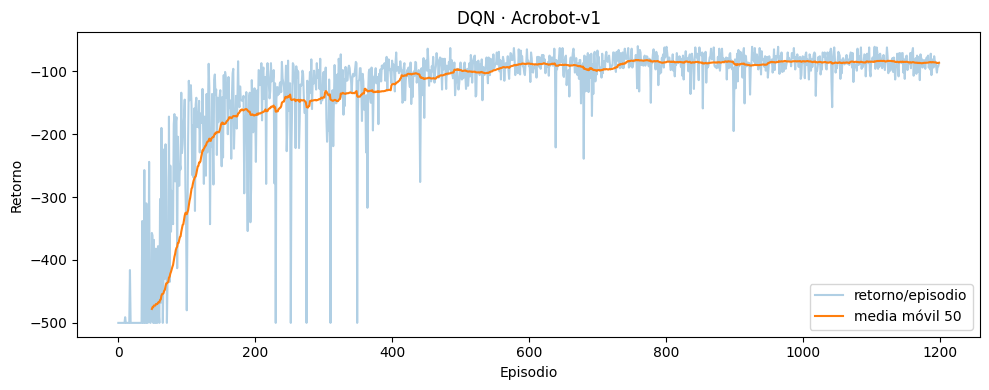

Curva guardada en: artifacts/dqn_learning_curve_1200ep.png


In [16]:

curve_path = plot_training(history, window=(5 if RUN_MODE == "smoke" else 50))
print("Curva guardada en:", curve_path)


### Lo que muestra la curva

La franja azul son los retornos episodio a episodio y la línea naranja su media móvil de cincuenta.
El ascenso es pronunciado hasta el episodio 400 aproximadamente y después se aplana, lo que coincide
con lo que decía la traza numérica.

Las caídas verticales hasta −500 que se ven en la primera mitad son los episodios truncados: el
agente agotó los quinientos pasos sin levantar el brazo. Se vuelven cada vez más raras y desaparecen
por completo pasado el episodio 350. En la segunda mitad la franja azul se estrecha alrededor de la
línea naranja, y esa reducción del ancho es la forma visual de la caída de la desviación estándar.


## El resumen de la corrida

Consolidamos en un solo objeto las cifras de entrenamiento y evaluación que hemos ido viendo por
separado.


In [17]:

last_n = min(100, len(history["returns"]))
run_summary = {
    "mode": RUN_MODE,
    "train_episodes": len(history["returns"]),
    "train_mean_last_n": float(np.mean(history["returns"][-last_n:])),
    "train_median_last_n": float(np.median(history["returns"][-last_n:])),
    "train_terminal_rate": float(np.mean(history["terminated"])),
    "train_truncation_rate": float(np.mean(history["truncated"])),
    "eval_mean_return": metrics["mean_return"],
    "eval_median_return": metrics["median_return"],
    "eval_sd_return": metrics["sd_return"],
    "eval_mean_steps": metrics["mean_steps"],
    "eval_terminal_rate": metrics["terminal_rate"],
    "training_seconds": history["seconds"],
}
print(json.dumps(run_summary, indent=2))
with open(ARTIFACT_DIR/f"run_summary_{RUN_CFG.episodes}ep.json","w") as f:
    json.dump(run_summary,f,indent=2)


{
  "mode": "full",
  "train_episodes": 1200,
  "train_mean_last_n": -85.68,
  "train_median_last_n": -85.0,
  "train_terminal_rate": 0.9558333333333333,
  "train_truncation_rate": 0.045,
  "eval_mean_return": -80.96,
  "eval_median_return": -78.5,
  "eval_sd_return": 12.518204925046344,
  "eval_mean_steps": 81.96,
  "eval_terminal_rate": 1.0,
  "training_seconds": 298.71935391426086
}


El resumen deja en un solo objeto lo que hace falta para contrastar el documento: modo, semilla, episodios, pasos de entorno, actualizaciones de la red y las métricas de evaluación. Es el archivo que `acrobot verify` lee para comprobar que el texto y la corrida dicen lo mismo.


## Resultados

El agente resuelve Acrobot-v1. Sobre cien episodios de evaluación con estados iniciales nuevos
alcanza la meta en todos, con un retorno medio de −80,96 frente al umbral oficial de −100 y al suelo
de −500 de una política aleatoria. Son 81,96 pasos de media: la diferencia de un punto entre pasos y
retorno es el paso final, el único que no descuenta. Durante el entrenamiento la tasa de terminación
verdadera fue del 95,6 % global y del 100 % en los últimos cien episodios; el último episodio
truncado fue el 350, y después de ese no hubo ninguno.


![Las cinco semillas](../resultados/dqn_5_semillas.png)

*Izquierda: las cinco curvas de entrenamiento, indistinguibles a partir del episodio 600. Derecha: las cinco cajas de evaluación, prácticamente alineadas. Es la evidencia visual de que el resultado no depende de la inicialización.*


Repetimos el experimento completo con cinco semillas, cambiando únicamente el valor de `seed`. Las
cinco superan el umbral y suman 500 terminaciones verdaderas de 500 episodios evaluados. La
desviación entre las cinco medias es de 1,82, y no conviene compararla de frente con el 15,47 de
dentro de cada semilla porque son granularidades distintas: el error estándar de la media de una
semilla es 15,47/10 ≈ 1,55, prácticamente igual al 1,82 observado, que es justo lo que se esperaría
si las cinco políticas fueran equivalentes. Eso permite afirmar que el procedimiento, y no solo este
agente en particular, resuelve el entorno. Dónde queda entonces la dispersión es otra pregunta.
Mirando la matriz de 5 semillas × 100 estados, la desviación de las cien medias por estado (7,58) es
exactamente la que produciría el residuo por sí solo, así que lo que queda no es un efecto del entorno
común a las cinco políticas sino interacción: cuánto le cuesta a *esta* política *ese* estado. El
README lo desarrolla en §10.1.

Cada una de esas cinco corridas es un entrenamiento completo. Quedan guardadas en
`resultados/semillas/` —un JSON por semilla y el agregado en `RESUMEN_5_SEMILLAS.json`— junto con la
figura de las cinco curvas y los cinco boxplots, `resultados/dqn_5_semillas.png`, y se reproducen con
`acrobot train --mode full --seed N`.

Hay un punto que merece atención porque contradice la intuición. La pérdida creció durante todo el
entrenamiento, de 0,0062 a 0,4807, mientras el retorno mejoraba de −290 a −85, y eso no es un
deterioro. La pérdida mide el desacuerdo entre la red y un objetivo que se mueve. Al comienzo la
red está inicializada cerca de cero y el objetivo vale apenas `r + γ·max Q ≈ −1`: los dos términos
son pequeños y acertar es trivial. Cuando el agente aprende, los valores Q se separan dentro de la
banda que γ = 0,99 permite —de −100 a 0, y entre −63,1 y +6,5 en la red final— y distinguirlos se
vuelve un problema de regresión genuinamente más difícil. Ninguna de nuestras conclusiones se apoya en la pérdida.

No afirmamos optimalidad ni convergencia en sentido estricto. No existe una cota inferior conocida
para Acrobot con la que comparar el −60 del mejor episodio, y la media móvil sigue oscilando entre
−90,9 y −83,2 en los últimos trescientos episodios. Lo que la evidencia sostiene es estabilización.


## Poner a prueba la decisión que sostiene el trabajo

Hasta aquí hemos defendido con un argumento que el bootstrap solo debe anularse cuando el episodio
termina de verdad. El argumento es correcto, pero no dice cuánto pesa. Para saberlo entrenamos un
segundo agente idéntico en todo salvo en una línea —`buf.push(obs, a, r, nxt, terminated or
truncated)`— y lo evaluamos igual que al nuestro, con tres semillas cada uno.

Las corridas están guardadas; aquí solo las leemos y las comparamos.


In [18]:
import json
from pathlib import Path

import numpy as np

RES = Path("resultados")
SEMILLAS = [42, 43, 44]
resumen = json.loads((RES / "ablacion/RESUMEN_ABLACION.json").read_text())


def evaluacion_correcta(s):
    if s == 42:
        d = json.loads((RES / "evaluation_metrics_100ep.json").read_text())
        return d["mean_return"], d["terminal_rate"]
    d = json.loads((RES / f"semillas/resultado_seed_{s}.json").read_text())["evaluacion_greedy"]
    return d["retorno_medio"], d["tasa_terminacion"]


print(f"{'semilla':>8}   {'correcto':>18}   {'ablación':>18}")
correcto, ablacion = [], []
for s in SEMILLAS:
    rc, tc = evaluacion_correcta(s)
    a = resumen["semillas"][str(s)]
    correcto.append(rc)
    ablacion.append(a["evaluacion_retorno_medio"])
    print(f"{s:>8}   {rc:>9.2f} · {int(tc*100):3d}/100   "
          f"{a['evaluacion_retorno_medio']:>9.2f} · {int(a['evaluacion_tasa_terminacion']*100):3d}/100")

print(f"\n{'media':>8}   {np.mean(correcto):>9.2f}            {np.mean(ablacion):>9.2f}")
print(f"{'SD':>8}   {np.std(correcto, ddof=1):>9.2f}            {np.std(ablacion, ddof=1):>9.2f}")

# cuantos minilotes llegan a contener una transicion contaminada
h = json.loads((RES / "ablacion/ablacion_seed_42.json").read_text())
CAP, LOTE, INICIO = 100_000, 64, 1_000
paso, contaminadas, lotes, esperanza = 0, [], 0, 0.0
for n, truncado in zip(h["lengths"], h["truncated"]):
    for k in range(n):
        paso += 1
        if paso >= max(LOTE, INICIO):
            lotes += 1
            vivas = sum(1 for p in contaminadas if paso - p < CAP)
            if vivas:
                esperanza += 1 - (1 - vivas / min(paso, CAP)) ** LOTE
        if k == n - 1 and truncado:
            contaminadas.append(paso)

print(f"\ntransiciones contaminadas: {len(contaminadas)} de {sum(h['lengths']):,} pasos "
      f"= {len(contaminadas)/sum(h['lengths']):.3%} de lo recogido")
print(f"minilotes que llegan a contener alguna: {esperanza:,.0f} de {lotes:,} = {esperanza/lotes:.1%}")


 semilla             correcto             ablación
      42      -80.96 · 100/100      -80.62 · 100/100
      43      -79.33 · 100/100      -78.87 · 100/100
      44      -78.14 · 100/100     -134.05 ·  88/100

   media      -79.48               -97.85
      SD        1.42                31.37

transiciones contaminadas: 41 de 154,568 pasos = 0.027% de lo recogido
minilotes que llegan a contener alguna: 5,861 de 153,569 = 3.8%


![Retorno de evaluación por semilla, las dos versiones](../resultados/ablacion_truncacion.png)

*Izquierda: las dos curvas de entrenamiento de la semilla 42, que corren pegadas. Derecha: el retorno de evaluación de las tres semillas, donde la versión rota se descuelga en la 44.*


### Lo que muestra la comparación

Con las semillas 42 y 43 las dos versiones son indistinguibles: la diferencia está por debajo de
medio punto y ambas alcanzan la meta en los cien episodios. Con la semilla 44 la versión rota cae a
−134,05 y falla doce.

La media engaña menos que la desviación: **1,42 frente a 31,37**. El error no impide aprender, quita
fiabilidad.

Las dos últimas líneas de la salida explican por qué, y de paso corrigen la primera cuenta que
hicimos. El cambio toca una sola transición por episodio truncado —41 de las 154.568 transiciones recogidas, el 0,027 %— y con ese número la conclusión parecía ser que el error se diluye por pura rareza. Pero
lo que decide el daño no es qué fracción de la experiencia ocupan esas transiciones, sino en cuántas
actualizaciones entran: recorriendo la corrida paso a paso, **el 3,8 % de los minilotes llega a
contener alguna**, ciento cuarenta veces más. El error entra en uno de cada veintiséis gradientes, y
así deja de hacer falta la casualidad para explicar que una de tres semillas se rompa.

Lo que más nos inquieta del resultado es que en la semilla 44 la curva de entrenamiento no delata
nada: promedia −88,39 al final y no trunca ni una vez en los últimos doscientos episodios. El fallo
solo aparece al evaluar con la política congelada sobre estados iniciales que el agente no vio.


## Comparar con Double DQN

La sección anterior puso a prueba una decisión nuestra. Esta compara el agente con una variante
conocida del algoritmo, para saber si lo que entregamos se queda corto frente a algo que está a dos
líneas de distancia.

El objetivo de Bellman de DQN usa `max_a Q_target(s', a)`: la misma red elige la mejor acción y
estima cuánto vale. Con estimaciones ruidosas, el máximo cae de preferencia sobre el error positivo
más grande, así que el valor sale sistemáticamente alto. Double DQN separa las dos funciones —la red
en línea elige la acción, la red objetivo la evalúa— y con eso elimina esa componente optimista.

Entrenamos las dos versiones con las semillas 42, 43 y 44 y medimos dos cosas. La primera es el
retorno de evaluación, que dice cómo se comporta el agente. La segunda es el sesgo: lo que la red
predice para un estado frente al retorno descontado que el agente obtiene de verdad desde ahí. El
sesgo lo medimos en todos los estados que el agente visita, agrupados por cuántos pasos le faltan
para llegar a la meta, y esa decisión resultó ser la que cambió la conclusión.


In [19]:
import json
from pathlib import Path

RES = Path("resultados")
SEMILLAS = [42, 43, 44]
resumen = json.loads((RES / "double_dqn/RESUMEN_DOUBLE_DQN.json").read_text())
sesgo = json.loads((RES / "double_dqn/medicion_sesgo.json").read_text())

print(f"{'semilla':>8}   {'DQN':>9}   {'Double DQN':>11}   {'diferencia':>11}")
for s in SEMILLAS:
    a = resumen["dqn"]["retorno_por_semilla"][str(s)]
    b = resumen["double_dqn"]["retorno_por_semilla"][str(s)]
    print(f"{s:>8}   {a:>9.2f}   {b:>11.2f}   {b - a:>+11.2f}")
print(f"\n{'media':>8}   {resumen['dqn']['retorno_medio']:>9.2f}   "
      f"{resumen['double_dqn']['retorno_medio']:>11.2f}   "
      f"{resumen['diferencia_media']:>+11.2f}")

print("\nSesgo (valor predicho − retorno real) segun pasos que faltan para la meta")
tramos = ["0-19", "20-49", "50-79", "80-89", "90-99", "100+"]
print(f"{'':12}" + "".join(f"{t:>9}" for t in tramos))
for clave, nombre in (("dqn", "DQN"), ("double_dqn", "Double DQN")):
    por_tramo = sesgo["agregado"][clave]["sesgo_medio_por_tramo"]
    print(f"{nombre:12}" + "".join(f"{por_tramo[t]:>+9.2f}" for t in tramos))


 semilla         DQN    Double DQN    diferencia
      42      -80.96        -78.42         +2.54
      43      -79.33        -78.41         +0.92
      44      -78.14        -74.52         +3.62

   media      -79.48        -77.12         +2.36

Sesgo (valor predicho − retorno real) segun pasos que faltan para la meta
                 0-19    20-49    50-79    80-89    90-99     100+
DQN             -6.65    -4.70    -3.76    +1.29    +5.46    +9.53
Double DQN      -6.27    -6.51    -8.95    -2.64    +3.87   +11.25


![Desempeño y sesgo de las dos versiones](../resultados/double_dqn.png)

*Izquierda: los 100 episodios de evaluación de cada semilla, para los dos métodos. Derecha: el sesgo por tramo de pasos restantes, con los tramos a escala y el tamaño de muestra de cada uno; la zona sombreada es donde la cota aritmética del retorno real fuerza el signo.*


### Lo que muestran las dos mediciones

**En desempeño, Double DQN gana por poco y en las tres semillas**, con una diferencia media de 2,36
puntos. Tres semillas no permiten afirmar nada sobre el método, pero los 300 episodios están
pareados —el mismo estado inicial para las dos versiones— y sobre esos pares la diferencia es
significativa (t = 2,33). Es decir: *este* agente Double DQN es mejor que *este* agente DQN. Si
Double DQN es mejor como método, sigue sin poder afirmarse con tres semillas.

**En el sesgo encontramos lo contrario de lo que habíamos escrito al principio.** Nuestra primera
medición fue solo en el estado inicial y dio que ninguna de las dos versiones sobreestimaba: DQN se
quedaba corto por 6,03 puntos y Double DQN por 11,96. Al medir en todos los estados aparece que el
sesgo **cambia de signo con la dificultad**: cerca de la meta la red se queda corta, y en los estados
de los que aún faltan cien pasos o más el signo se invierte, +9,53 en DQN. El +11,25 de Double DQN no
lo ponemos al lado: promedia dos semillas y no tres, porque en la semilla 44 el agente nunca se quedó
tan lejos de la meta, y sus dos sumandos difieren en un factor de siete.

La columna del valor predicho dice por qué: de los 50 pasos en adelante lo que la red predice se
aplana mientras el retorno real sigue cayendo, así que el cruce lo produce el real y no una
predicción que suba. La red comprime el rango de la función de valor.

Y hay un límite que conviene decir antes que la interpretación: con cien pasos por delante el retorno
real no puede superar −63,03, mientras el valor mínimo que nuestras redes predicen ronda −62. **En
ese tramo el signo positivo estaba forzado por aritmética**, así que no lo leemos como
sobreestimación del máximo. Lo que sí sostiene la medición es que el sesgo tiene estructura y que
medirlo en un solo punto —el estado inicial— nos había dado la respuesta contraria.

Que Double DQN rinda algo mejor con valores más bajos no es contradictorio: la política sale del
`argmax`, y para elegir bien basta con ordenar las tres acciones, no con acertar su valor absoluto.


## ¿Hacía falta la red?

Todo el cuaderno da por sentado que este problema pide una red. El argumento está en «La red»: la
función Q depende de productos entre ángulos y velocidades, y una tabla no puede representar eso sin
discretizar. Es, otra vez, un argumento sin medir.

Q-learning tabular necesita estados discretos. La observación tiene seis componentes, pero el estado
físico real son cuatro: dos ángulos y dos velocidades. Los senos y cosenos son una reparametrización
que le conviene a una red y no a una tabla, así que recuperamos los ángulos con `atan2` y
discretizamos las cuatro variables. Todo lo demás es idéntico: 1.200 episodios, γ = 0,99, el mismo
decaimiento de ε y las mismas semillas de evaluación.

Antes de comparar probamos doce configuraciones —cuatro rejillas por tres tasas de aprendizaje— y
nos quedamos con la mejor. Un baseline mal ajustado que pierde no demuestra nada.


In [20]:
import json
from pathlib import Path

RES = Path("resultados")
resumen = json.loads((RES / "tabular/RESUMEN_TABULAR.json").read_text())
SEMILLAS = ["42", "43", "44"]

print(f"{'semilla':>8}   {'DQN':>9}   {'tabular':>9}   {'terminaciones':>15}   {'cobertura':>10}")
for s in SEMILLAS:
    t = resumen["por_semilla"][s]
    dqn = {"42": -80.96, "43": -79.33, "44": -78.14}[s]
    cob = t["estados_visitados"] / resumen["discretizacion"]["estados_totales"]
    print(f"{s:>8}   {dqn:>9.2f}   {t['retorno_medio']:>9.2f}   "
          f"{int(t['tasa_terminacion']*100):>7}/100        {cob:>9.1%}")

print(f"\n{'media':>8}   {resumen['dqn_mismas_semillas']['retorno_medio']:>9.2f}   "
      f"{resumen['agregado']['retorno_medio']:>9.2f}")

q = resumen["presupuesto_quintuplicado"]
print(f"\nCon {q['episodios']:,} episodios (cinco veces mas experiencia, semilla 42):")
print(f"  retorno {q['retorno_medio']:.2f} · terminaciones {int(q['tasa_terminacion']*100)}/100")
print(f"  estados visitados {q['estados_visitados']:,} de {q['estados_totales']:,} "
      f"({q['estados_visitados']/q['estados_totales']:.1%})")

barrido = json.loads((RES / "tabular/barrido_hiperparametros.json").read_text())
mejor = max(barrido, key=lambda r: r["eval_retorno"])
print(f"\nBarrido: {len(barrido)} configuraciones probadas. La mejor fue "
      f"{mejor['bins_angulo']}x{mejor['bins_velocidad']} con alpha={mejor['alpha']}, "
      f"y dio {mejor['eval_retorno']:.2f}.")
print("Ninguna alcanzo el umbral de -100.")


 semilla         DQN     tabular     terminaciones    cobertura
      42      -80.96     -166.21       100/100            11.1%
      43      -79.33     -205.31       100/100            10.6%
      44      -78.14     -214.43       100/100            10.9%

   media      -79.48     -195.32

Con 6,000 episodios (cinco veces mas experiencia, semilla 42):
  retorno -185.00 · terminaciones 100/100
  estados visitados 1,945 de 14,400 (13.5%)

Barrido: 12 configuraciones probadas. La mejor fue 12x10 con alpha=0.1, y dio -166.21.
Ninguna alcanzo el umbral de -100.


![Tabular frente a DQN](../resultados/tabular.png)

*Izquierda: el retorno de evaluación de las tres semillas para los dos métodos. Derecha: las doce configuraciones del barrido, ordenadas por retorno.*


### Lo que muestra la comparación

**El tabular resuelve Acrobot.** Alcanza la meta en los 300 episodios de evaluación, igual que el
DQN. Eso va primero porque cambia la pregunta: el entorno no exige una red para ser resuelto.

**Y aun así le cuesta dos veces y media más llegar.** −195,32 contra −79,48, y ninguna de las tres
semillas alcanza el umbral de −100. Tampoco lo alcanzó ninguna de las doce configuraciones del
barrido.

**La tabla queda mayormente vacía, y esa fue nuestra primera explicación.** El agente visita
alrededor del 11 % de las 14.400 celdas —un 26 % si se descuentan los bins de velocidad que el
sistema físico nunca alcanza, que son la mayor parte de la tabla—, y escribimos que ahí estaba la
causa: ante una celda en cero la política elige por desempate, sin información.

**No se sostuvo.** El barrido que parecía respaldarlo corrió con una sola semilla, así que repetimos
las cuatro rejillas con las semillas 42, 43 y 44 (`resultados/tabular/rejillas_tres_semillas.json`).
Con tres semillas, 8×6 promedia −192,90 y 12×10 promedia −195,32: 2,4 puntos de distancia frente a
desviaciones entre semillas de 12,94 y 25,62, cuando con una sola habíamos visto 19,8 puntos de
ventaja para 12×10 y los habíamos leído como si significaran algo. La rejilla que cubre 1,7 veces más
de su tabla no rinde peor: rinde igual. **Cuál es el mecanismo no lo sabemos**, y preferimos dejarlo
escrito así antes que rellenarlo con una historia plausible.

**Lo que sí sobrevive a las tres semillas** es lo que pasa al afinar: por encima de 12×10 el retorno
empeora de forma consistente y el tabular deja de resolver el entorno —285 y 252 terminaciones de
300, contra 299 y 300 de las dos rejillas gruesas—. Eso cierra la salida fácil de «con más resolución
la tabla funcionaría».

**Y tampoco es falta de presupuesto.** Con 6.000 episodios —cinco veces más experiencia— el retorno
no mejora y la cobertura sube apenas del 11 % al 13,5 % nominal. La política greedy concentra las
visitas en la misma región, así que las celdas nuevas son las que menos importan.

Una nota sobre la comparación misma: *el mismo número de episodios no es el mismo número de pasos*.
Los episodios del tabular son más largos, así que sus 1.200 le costaron 388.550 pasos de entorno
contra los 158.451 del DQN. La comparación le da al tabular 2,5 veces más interacción, no menos.

La conclusión que nos llevamos: la red no era indispensable para resolver el entorno, y sí lo fue
para alcanzar el criterio de resolución con este presupuesto.


## Lo que más nos costó

Entender que `terminated` y `truncated` detienen el mismo bucle de Python y significan cosas
distintas para Bellman. Un episodio truncado en el paso 500 no implica que ese estado tenga valor
futuro cero; solo significa que un límite externo interrumpió la experiencia.

Lo difícil vino después, y fue resistirnos a exagerar la consecuencia. Habíamos escrito que era la
decisión determinante del trabajo, razonando que si la falsedad se propaga hacia atrás por toda la
trayectoria el daño tiene que ser grande. Entrenar la versión equivocada nos corrigió tres veces. La
primera corrida salió indistinguible de la buena —−80,62 contra −80,96— y estuvimos a punto de
escribir que la distinción daba igual; dos semillas más mostraron que en una de las tres el agente
falla 12 de 100 episodios de evaluación sin que la curva de entrenamiento lo delate; y al buscar por
qué, la primera cuenta que hicimos —la fracción de transiciones afectadas— medía lo que no importaba.
Nos equivocamos primero por exagerar el efecto, estuvimos a punto de equivocarnos después por
negarlo, y por poco lo explicamos con el número equivocado: las tres veces por concluir desde un
argumento, desde una sola corrida o desde la cuenta más cómoda. La magnitud de un error se mide, no
se deduce; medirla una sola vez no es medirla; y medir algo no es lo mismo que medir lo que importa.

La segunda dificultad fue no corregir el entrenamiento demasiado pronto. Al ver la pérdida crecer,
la reacción intuitiva era bajar el learning rate o dar por hecha una inestabilidad. Habría sido
intervenir sobre una corrida que estaba mejorando, guiados por una lectura equivocada de la métrica.
Antes de tocar un hiperparámetro tuvimos que volver a la ecuación, separar retorno de error de
regresión y preguntarnos qué medía cada serie.


## Alcance y trabajo futuro

El agente que entregamos es un DQN sin extensiones: sin Dueling, sin replay priorizado y sin ninguna
técnica especial de exploración. Resuelve el entorno con ε-greedy simple porque en Acrobot la
exploración aleatoria encuentra la meta desde temprano —diez de los primeros cincuenta episodios
llegaron— y el buffer contiene trayectorias exitosas casi desde el arranque.

Las limitaciones son de alcance, no de ejecución. El replay es uniforme y no probamos agregación por
vecindad ni *tile coding*, que son las representaciones intermedias entre una tabla y una red y las
que más curiosidad nos dejaron después de la comparación anterior.

Las dos preguntas que dejamos abiertas tienen que ver con el tamaño de las muestras. Los dos
experimentos de control corrieron con tres semillas cada uno: suficiente para ver que el manejo de
la truncación afecta a la fiabilidad y que Double DQN mejora poco, pero no para cuantificar
ninguna de las dos cosas con un intervalo. Y Dueling DQN queda sin probar: factoriza el valor del
estado y la ventaja de cada acción, aunque con solo tres acciones el margen que cabe esperar es
estrecho.
